In [1]:
import h5py
import numpy as np
import pandas as pd
from scipy.sparse import csc_matrix
import statsmodels.api as sm
import pandas as pd
import re
import anndata as ad
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.sparse import issparse
import scanpy as sc

In [3]:

def load_allen_smartseq_h5(path, group="data/t_exon"):
    with h5py.File(path, "r") as f:
        genes = [g.decode() for g in f["gene_names"][:]]
        cells = [s.decode() for s in f["sample_names"][:]]
        G, C = len(genes), len(cells)

        grp = f[group]
        dims = tuple(grp["dims"][:])     # e.g. (45768, 73363)
        i = grp["i"][:]
        p = grp["p"][:]
        x = grp["x"][:]

        # Build matrix as stored (CSC = columns compressed)
        X = csc_matrix((x, i, p), shape=dims)

        # Infer which axis is cells vs genes from p-length (ncols = len(p)-1)
        ncols = len(p) - 1
        if ncols == G:
            # columns are genes, rows must be cells -> OK for AnnData
            pass
        elif ncols == C:
            # columns are cells -> transpose so rows=cells, cols=genes
            X = X.T
        else:
            # Fallback: try dims against known counts
            if dims[0] == C and dims[1] == G:
                pass
            elif dims[0] == G and dims[1] == C:
                X = X.T
            else:
                raise ValueError(
                    f"Can't infer orientation: dims={dims}, genes={G}, cells={C}, ncols={ncols}"
                )

    # Now X is cells × genes
    return ad.AnnData(
        X=X,
        obs=pd.DataFrame(index=cells),   # cells
        var=pd.DataFrame(index=genes)    # genes
    )

# Usage
adata = load_allen_smartseq_h5("Data/expression_matrix.hdf5")
print(adata)  # should report n_obs == len(cells), n_vars == len(genes)


# 1) Load metadata (suppress dtype warning)
meta = pd.read_csv("Data/metadata.csv", low_memory=False)

# 2) Clean keys and index by sample_name
meta["sample_name"] = meta["sample_name"].astype(str).str.strip()
meta = meta.set_index("sample_name")

# 3) Report overlap so you know coverage
in_meta = adata.obs_names.isin(meta.index)
print(f"Matched {in_meta.sum():,} / {adata.n_obs:,} cells "
      f"({100*in_meta.mean():.1f}%) to metadata")

# 4) Safe join: reindex to adata.obs_names (no KeyError; missing → NaN)
meta_aligned = meta.reindex(adata.obs_names)
adata.obs = adata.obs.join(meta_aligned)

print(adata.obs["class_label"].unique())
print(adata.obs["subclass_label"].unique()[:20])
# 5) Filter to pyramidal cells
# Prefer subclass_label (IT/ET/CT). Fallback to cluster_label regex if needed.
mask_glut = adata.obs["class_label"].astype(str) == 'GABAergic'
adata = adata[mask_glut].copy()
pyr_subclasses = {"Pvalb", "Sst", "Vip"}
has_subclass = "subclass_label" in adata.obs.columns

if has_subclass:
    mask_pyr = adata.obs["subclass_label"].astype(str).str.upper().isin(pyr_subclasses)
else:
    # Fallback: parse from cluster_label like "197_L5 IT CTX"
    pat = re.compile(r"\b(IT|SST|VIP)\b", flags=re.IGNORECASE)
    mask_pyr = adata.obs["cluster_label"].astype(str).str.contains(pat)

adata_pyr = adata[mask_pyr].copy()
print(adata_pyr)



AnnData object with n_obs × n_vars = 73363 × 45768
Matched 73,347 / 73,363 cells (100.0%) to metadata
['Glutamatergic' 'GABAergic' 'Non-Neuronal' nan]
['L5 PT CTX' 'L5 IT CTX' 'L4/5 IT CTX' 'L6 IT CTX' 'L6 CT CTX'
 'L5/6 NP CTX' 'Pvalb' 'Vip' 'L2/3 IT CTX' 'Lamp5' 'Sst' 'Oligo'
 'Sst Chodl' 'Sncg' 'Car3' 'Astro' 'L6b CTX' 'Endo' 'L2/3 IT PPP'
 'SMC-Peri']
AnnData object with n_obs × n_vars = 0 × 45768
    obs: 'donor_sex_id', 'donor_sex_label', 'donor_sex_color', 'region_id', 'region_label', 'region_color', 'platform_label', 'cluster_order', 'cluster_label', 'cluster_color', 'subclass_order', 'subclass_label', 'subclass_color', 'neighborhood_id', 'neighborhood_label', 'neighborhood_color', 'class_order', 'class_label', 'class_color', 'exp_component_name', 'external_donor_name_label', 'full_genotype_label', 'facs_population_plan_label', 'injection_roi_label', 'injection_materials_label', 'injection_method_label', 'injection_type_label', 'full_genotype_id', 'full_genotype_color', 'extern

In [4]:
genes_of_interest = ['Fos', 'Fosb', 'Junb', 'Egr1', 'Egr2', 'Npas4',
                     'Arc', 'Nr4a1', 'Nr4a2', 'Bdnf', 'Nptx2', 'Syt4',
                     'Camk2g', 'Rgs4', 'Dusp1', 'Atf3', 'Crem', 
                     'Gadd45b', 'Gadd45g', 'Prkcz']



found = [g for g in genes_of_interest if g in adata.var_names]



if not found:
    raise ValueError("None of the target genes are in adata.var_names")


#(1) CPM normalization
sc.pp.normalize_total(adata, target_sum=1e6)

# (2) log transform
sc.pp.log1p(adata)

X = adata[:, found].X
X = X.toarray() if issparse(X) else np.asarray(X)

# Z-score each gene across cells
expr_z = (X - X.mean(axis=0)) / (X.std(axis=0) + 1e-8)

# Per-cell plasticity score = mean z across genes
adata.obs["plasticity_score"] = expr_z.mean(axis=1)

print("genes found:", found)
print("Plasticity score range:", adata.obs["plasticity_score"].min(), adata.obs["plasticity_score"].max())


/home/peter/.local/lib/python3.10/site-packages/numba/np/ufunc/parallel.py:371: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


genes found: ['Fos', 'Fosb', 'Junb', 'Egr1', 'Egr2', 'Npas4', 'Arc', 'Nr4a1', 'Nr4a2', 'Bdnf', 'Nptx2', 'Syt4', 'Camk2g', 'Rgs4', 'Dusp1', 'Atf3', 'Crem', 'Gadd45b', 'Gadd45g', 'Prkcz']
Plasticity score range: -1.036868789123741 2.386382169569571


/tmp/ipykernel_11392/3205084806.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


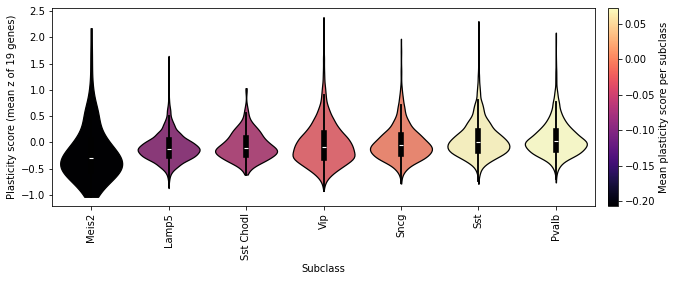

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

df = adata.obs.copy()

group_col = "subclass_label"      # or whatever you’re using
score_col = "plasticity_score"

# 1) Order subclasses by median score (looks nicer)
order = (
    df.groupby(group_col)[score_col]
      .median()
      .sort_values()
      .index
)

# 2) Compute mean score per subclass for coloring
group_means = df.groupby(group_col)[score_col].mean()

# 3) Build a palette: subclass → color based on mean score
cmap = plt.cm.magma  # or any matplotlib colormap
norm = plt.Normalize(vmin=group_means.min(), vmax=group_means.max())

palette = {cls: cmap(norm(mu)) for cls, mu in group_means.items()}

# 4) Violin plot with custom colors (palette)
fig, ax = plt.subplots(figsize=(10, 4))
sns.violinplot(
    data=df,
    x=group_col,
    y=score_col,
    order=order,
    palette=palette,
    cut=0,
    inner="box",   # or "quartile" / None
    ax=ax,
)

ax.set_xlabel("Subclass")
ax.set_ylabel("Plasticity score (mean z of 19 genes)")
plt.xticks(rotation=90)

# 5) Add colorbar showing mean score legend
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax, pad=0.02)
cbar.set_label("Mean plasticity score per subclass")

plt.tight_layout()
plt.savefig("figures/Fig1S_GABA_Mean plasticity score per subclass.png")
plt.savefig("figures/Fig1S_GABA_Mean plasticity score per subclass.svg")

plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'figures/umapfigures/Fig1S_GABA_Global_UMAP.svg'

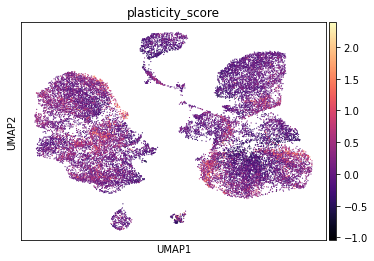

In [7]:
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)

sc.pl.umap(adata, color="plasticity_score", cmap="magma", save="figures/Fig1S_GABA_Global_UMAP.svg")



In [8]:
from scipy.stats import spearmanr

for axis in ["X_umap1", "X_umap2"]:
    corr, p = spearmanr(adata.obsm["X_umap"][:, 0 if axis=="X_umap1" else 1],
                        adata.obs["plasticity_score"])
    print(axis, corr, p)


X_umap1 -0.151208331469897 2.675925457468558e-116
X_umap2 -0.048106337310468636 4.004083245965692e-13


FileNotFoundError: [Errno 2] No such file or directory: 'figures/umapfigures/Fig1S_GABA_UMAP.svg'

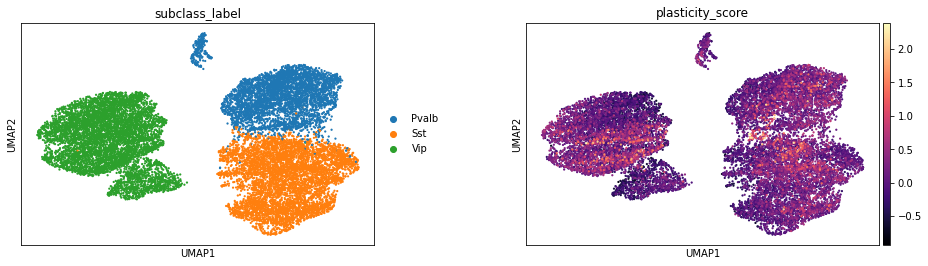

In [10]:
adata_l5 = adata[adata.obs["subclass_label"].isin(["Pvalb", "Sst", "Vip"]), :].copy()


# 2) Recalculate PCA + neighbors for the subset
sc.pp.pca(adata_l5)
sc.pp.neighbors(adata_l5, n_neighbors=15, n_pcs=20)

# 3) Compute UMAP
sc.tl.umap(adata_l5)

# 4) Plot subclass and plasticity score
sc.pl.umap(
    adata_l5,
    color=["subclass_label", "plasticity_score"],
    cmap="magma",
    wspace=0.3,
    size=20,           # small points look better for zoomed subsets
    save="figures/Fig1S_GABA_UMAP.svg"
)


In [ ]:

X = adata[:, found].X.toarray()
corr = np.corrcoef(X.T)

sns.clustermap(
    corr,
    xticklabels=found,
    yticklabels=found,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)


['Camk2g', 'Atf3', 'Nr4a2', 'Gadd45g', 'Prkcz', 'Syt4', 'Rgs4', 'Crem', 'Dusp1', 'Fos', 'Nr4a1', 'Egr1', 'Arc', 'Junb', 'Egr2', 'Npas4', 'Fosb', 'Gadd45b', 'Bdnf', 'Nptx2']
Mean within-IEG corr: 0.41729621466111677


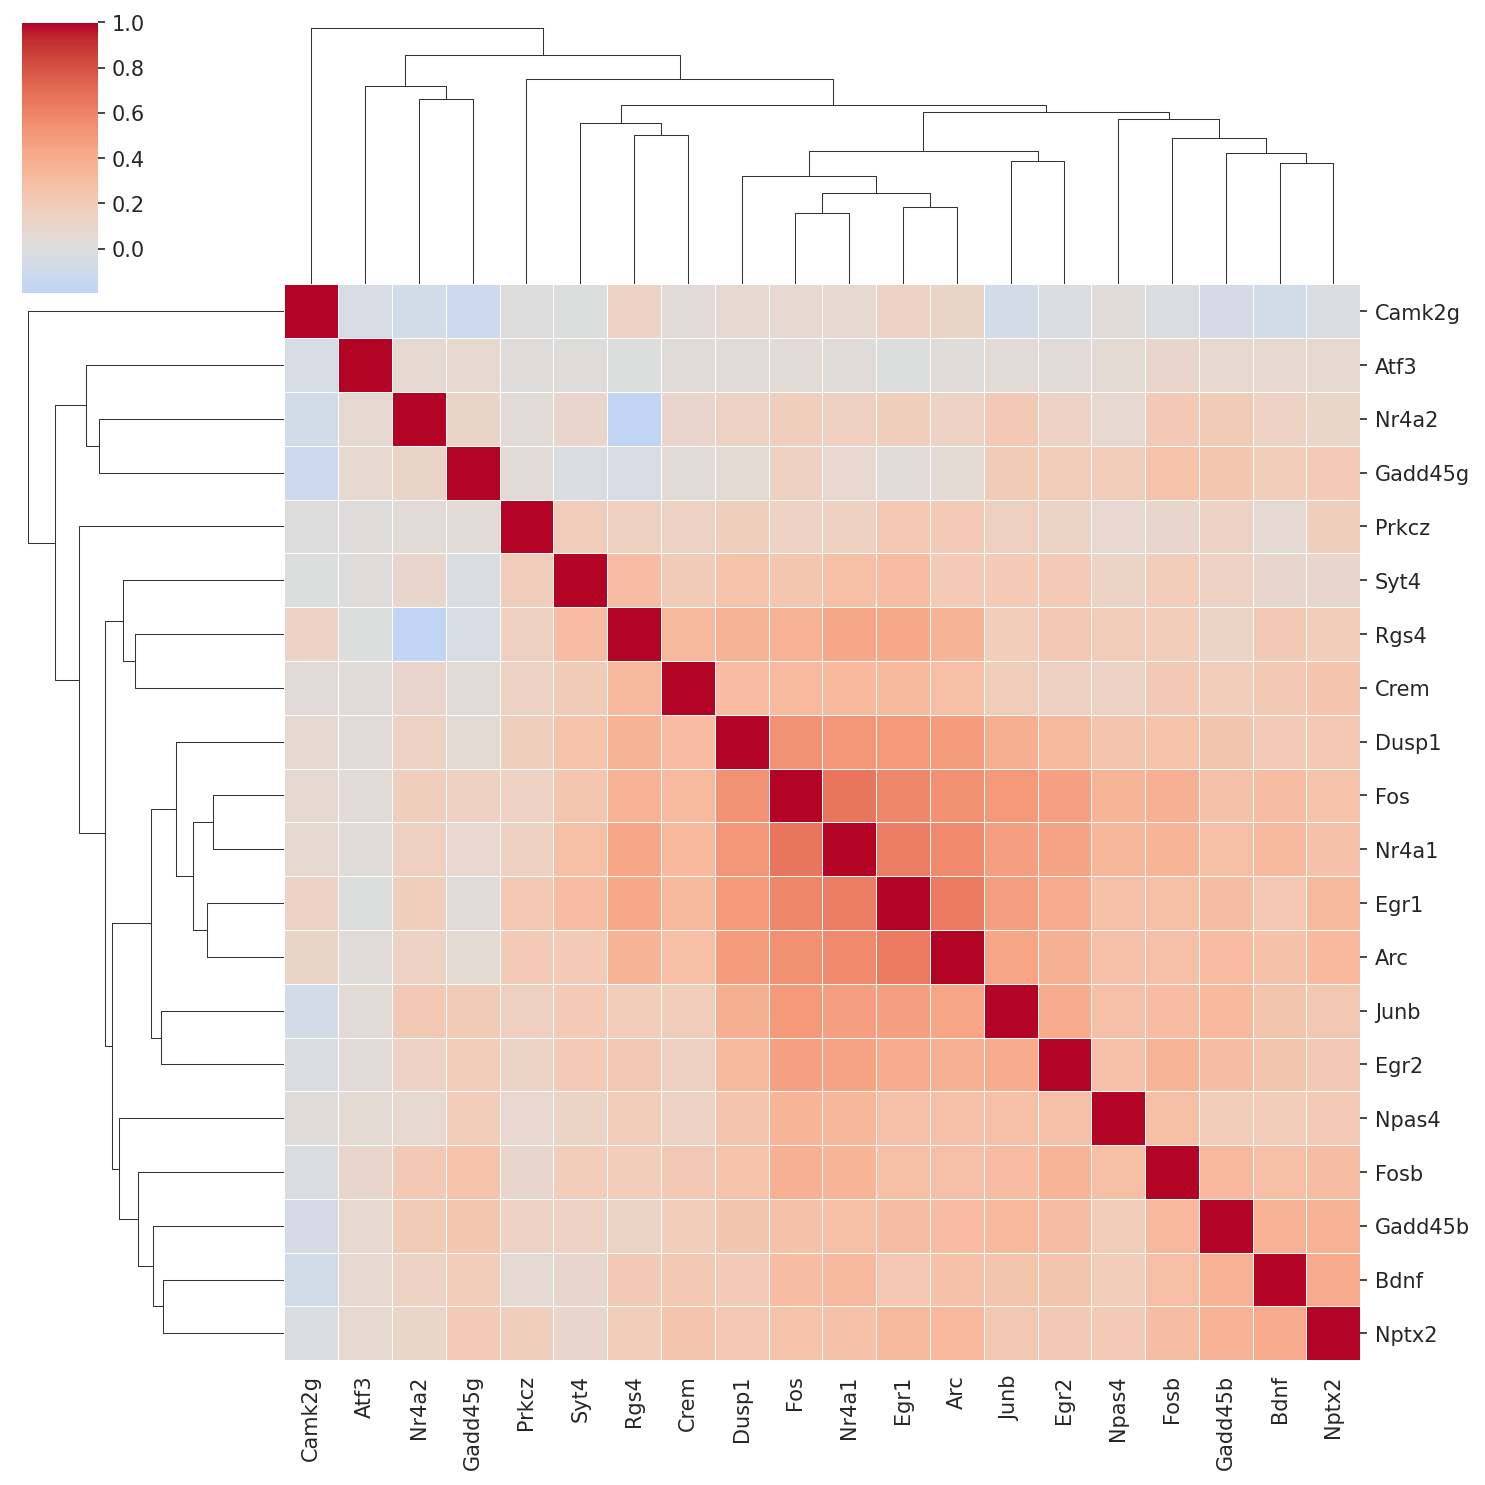

In [62]:
cg = sns.clustermap(
    corr,
    xticklabels=found,
    yticklabels=found,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

idx = cg.dendrogram_row.reordered_ind
ordered_genes = [found[i] for i in idx]
print(ordered_genes)

corr_ordered = corr[np.ix_(idx, idx)]

# Example: indices for IEG cluster in this ordered list (you can pick by name)
IEG = ["Fos", "Fosb", "Junb", "Egr1", "Egr2", "Npas4", "Nr4a1", "Arc"]
IEG_idx = [ordered_genes.index(g) for g in IEG]

# mean IEG–IEG correlation (off-diagonal)
ie_mask = np.ix_(IEG_idx, IEG_idx)
ie_corr = corr_ordered[ie_mask]
mean_ie_within = ie_corr[np.triu_indices_from(ie_corr, k=1)].mean()
print("Mean within-IEG corr:", mean_ie_within)



In [11]:
import statsmodels.api as sm
import pandas as pd

# choose the column name that actually exists
print(adata.obs.columns)  # check once
subclass_col = "subclass_label"   # adjust if different

# build a small tidy dataframe
df = adata.obs[[subclass_col, "plasticity_score"]].dropna()

# one-hot encode subclass
X = pd.get_dummies(df[subclass_col].astype(str), drop_first=True)

# add intercept
X = sm.add_constant(X)

# response variable
y = df["plasticity_score"].astype(float)

# fit model
model = sm.OLS(y, X).fit()

print("R²:", model.rsquared)
print("Adjusted R²:", model.rsquared_adj)
print(model.summary().tables[1])  # coefficients table
r2_subclass = model.rsquared


Index(['donor_sex_id', 'donor_sex_label', 'donor_sex_color', 'region_id',
       'region_label', 'region_color', 'platform_label', 'cluster_order',
       'cluster_label', 'cluster_color', 'subclass_order', 'subclass_label',
       'subclass_color', 'neighborhood_id', 'neighborhood_label',
       'neighborhood_color', 'class_order', 'class_label', 'class_color',
       'exp_component_name', 'external_donor_name_label',
       'full_genotype_label', 'facs_population_plan_label',
       'injection_roi_label', 'injection_materials_label',
       'injection_method_label', 'injection_type_label', 'full_genotype_id',
       'full_genotype_color', 'external_donor_name_id',
       'external_donor_name_color', 'facs_population_plan_id',
       'facs_population_plan_color', 'injection_materials_id',
       'injection_materials_color', 'injection_method_id',
       'injection_method_color', 'injection_roi_id', 'injection_roi_color',
       'injection_type_id', 'injection_type_color',
       'cell

R² subclass: 0.03386663242578136
R² layer:    0.04079898213028288
R² region:   0.12109715249837527
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0235      0.006      3.772      0.000       0.011       0.036
L1             0.0134      0.011      1.218      0.223      -0.008       0.035
L1/2/3         0.1055      0.017      6.077      0.000       0.071       0.140
L1/2/3/4       0.2651      0.015     17.361      0.000       0.235       0.295
L2             0.4985      0.049     10.113      0.000       0.402       0.595
L2/3           0.0074      0.009      0.857      0.392      -0.009       0.024
L2/3/4         0.7181      0.052     13.699      0.000       0.615       0.821
L2/3/5         0.0576      0.080      0.716      0.474      -0.100       0.215
L4             0.0503      0.017      3.007      0.003       0.018       0.083
L4/5          -0.2261      0.175

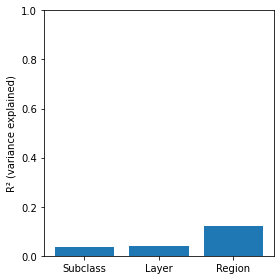

In [12]:
import statsmodels.api as sm
import pandas as pd

def r2_for_factor(adata, factor_col, response_col="plasticity_score"):
    """Return R² and fitted model for a categorical factor."""
    df = adata.obs[[factor_col, response_col]].dropna()

    # one-hot encode factor
    X = pd.get_dummies(df[factor_col].astype(str), drop_first=True)

    # add intercept
    X = sm.add_constant(X)

    y = df[response_col].astype(float)

    model = sm.OLS(y, X).fit()
    return model.rsquared, model
r2_subclass, model_subclass = r2_for_factor(adata, "subclass_label")
r2_layer,    model_layer    = r2_for_factor(adata, "cortical_layer_label")
r2_region,   model_region   = r2_for_factor(adata, "region_label")

print("R² subclass:", r2_subclass)
print("R² layer:   ", r2_layer)
print("R² region:  ", r2_region)
print(model_layer.summary().tables[1])
print(model_region.summary().tables[1])
import matplotlib.pyplot as plt

labels = ["Subclass", "Layer", "Region"]
r2_vals = [r2_subclass, r2_layer, r2_region]

plt.figure(figsize=(4, 4))
plt.bar(labels, r2_vals)
plt.ylabel("R² (variance explained)")
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


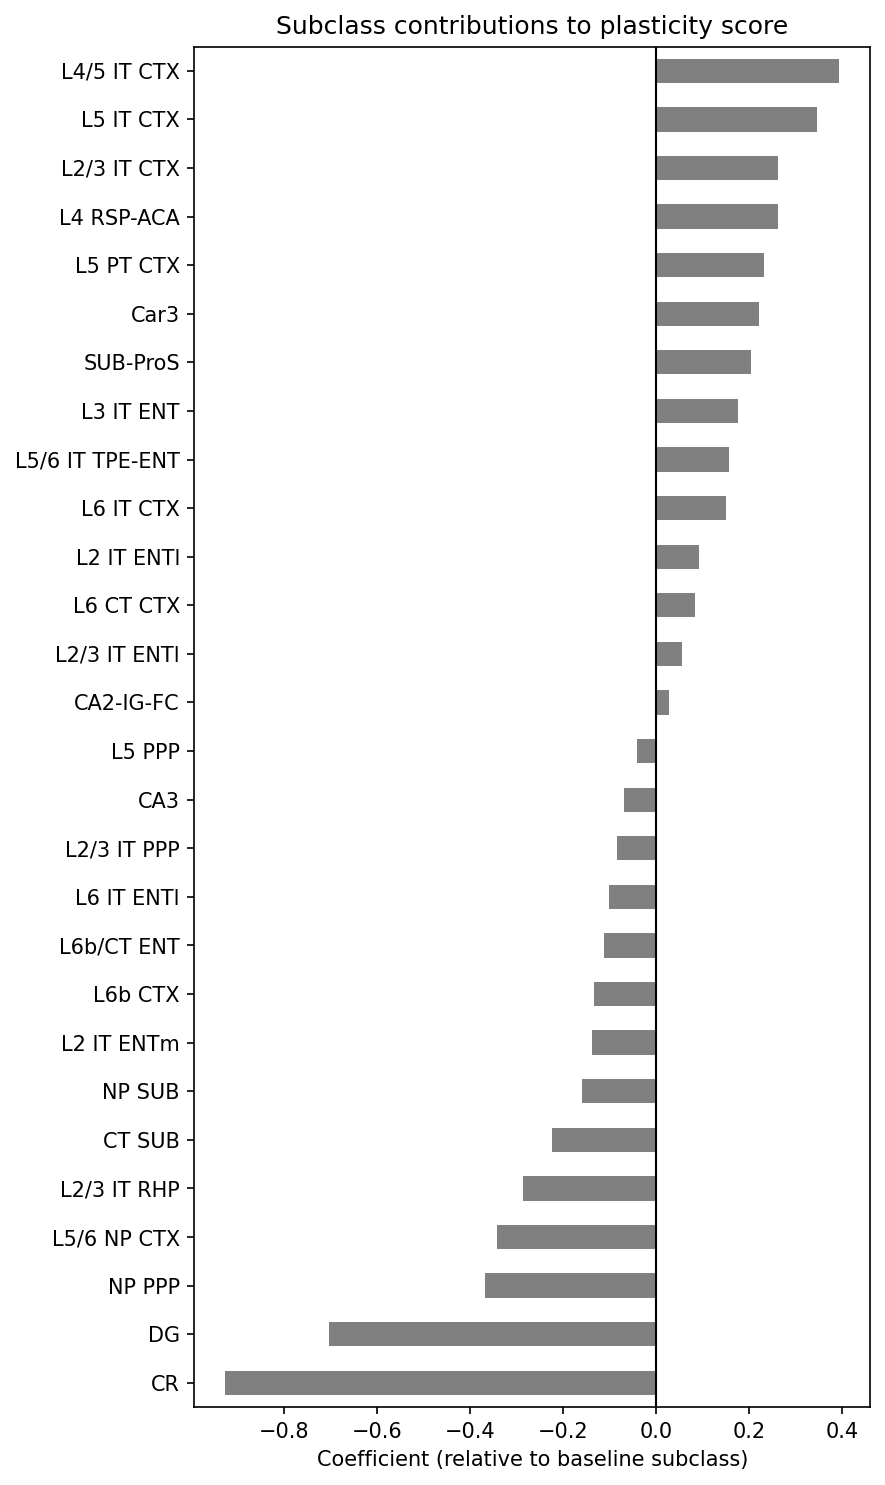

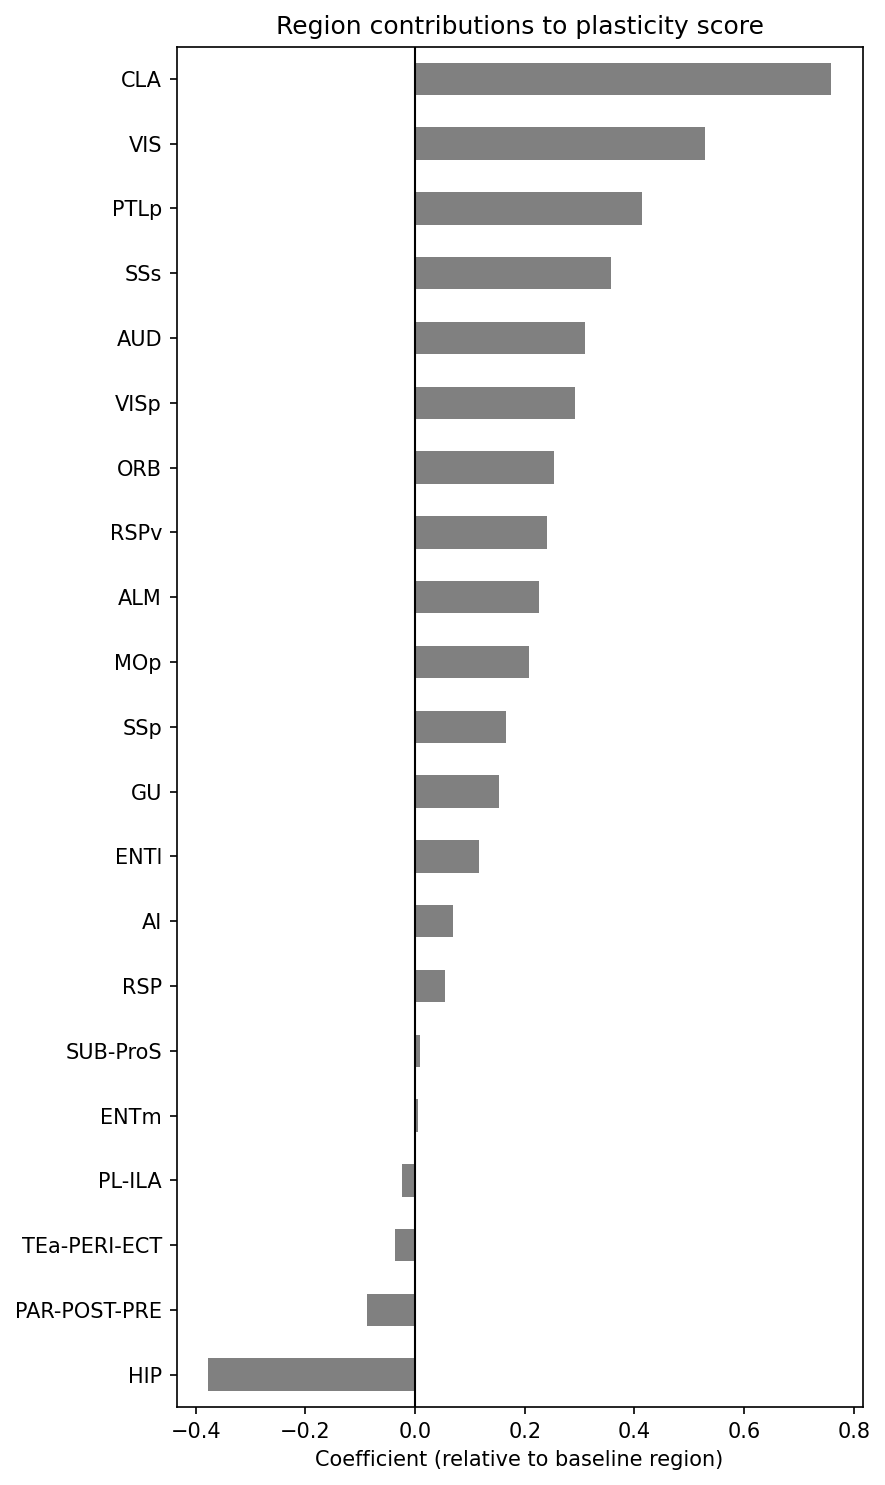

In [15]:
coef_table = model_subclass.summary().tables[1]
coef_df = coef_table.as_html()

# Easier: pull coefficients directly
subclass_coefs = model_subclass.params.drop("const")
subclass_coefs = subclass_coefs.sort_values()

plt.figure(figsize=(6, 10), dpi=150)
subclass_coefs.plot(kind="barh", color="gray")
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Coefficient (relative to baseline subclass)")
plt.title("Subclass contributions to plasticity score")
plt.tight_layout()
plt.savefig("figures/Fig1_Subclass contributions to plasticity score.png")
plt.savefig("figures/Fig1_Subclass contributions to plasticity score.svg")
plt.show()
region_coefs = model_region.params.drop("const").sort_values()

plt.figure(figsize=(6, 10), dpi=150)
region_coefs.plot(kind="barh", color="gray")
plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Coefficient (relative to baseline region)")
plt.title("Region contributions to plasticity score")
plt.tight_layout()
plt.savefig("figures/Fig1_Region contributions to plasticity score.png")
plt.savefig("figures/Fig1_Region contributions to plasticity score.svg")
plt.show()


In [ ]:
adata.obs["plasticity_score_scaled"] = (
    adata.obs.groupby("subclass_label")["plasticity_score"]
    .transform(lambda x: (x - x.mean()) / (x.std() + 1e-8))
)


plt.figure(figsize=(10, 5))
sns.violinplot(data=adata.obs, x="subclass_label", y="plasticity_score_scaled", cut=0)

plt.xticks(rotation=90)
plt.show()

subclass_label
L4/5 IT CTX        0.267794
L5 IT CTX          0.219468
L2/3 IT CTX        0.135934
L4 RSP-ACA         0.135387
L5 PT CTX          0.105574
Car3               0.094226
SUB-ProS           0.078289
L3 IT ENT          0.048899
L5/6 IT TPE-ENT    0.031173
L6 IT CTX          0.024972
Name: plasticity_score, dtype: float64


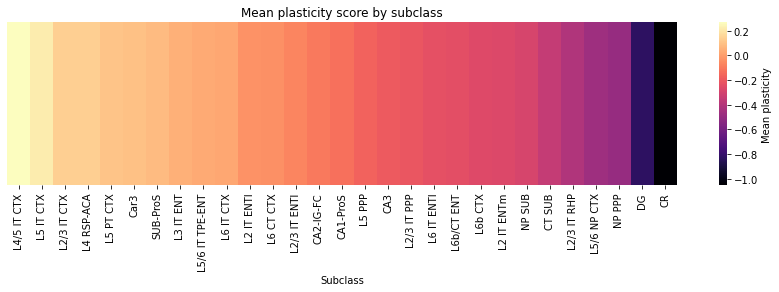

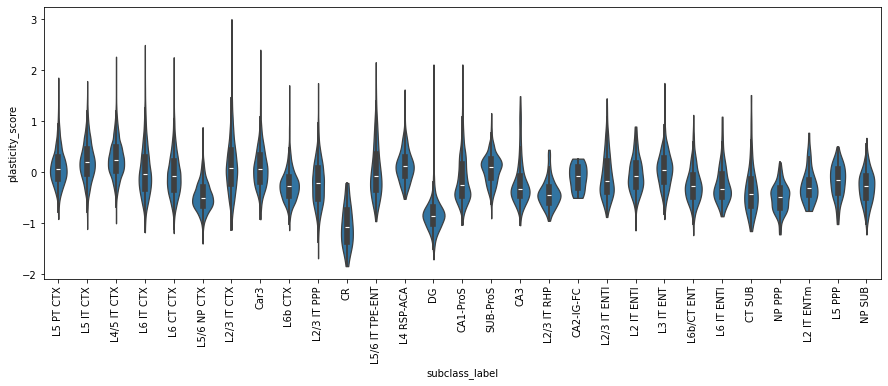

In [32]:
avg = (
    adata.obs.groupby("subclass_label")["plasticity_score"]
    .mean()
    .sort_values(ascending=False)
)
print(avg.head(10))

plt.figure(figsize=(15, 3))
sns.heatmap(avg.to_frame().T, cmap="magma", cbar_kws={"label": "Mean plasticity"})
plt.yticks([])
plt.xlabel("Subclass")
plt.title("Mean plasticity score by subclass")
plt.show()

plt.figure(figsize=(15, 5))
sns.violinplot(data=adata.obs, x="subclass_label", y="plasticity_score", cut=0)

plt.xticks(rotation=90)
plt.show()

/tmp/ipykernel_8231/1041005322.py:5: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


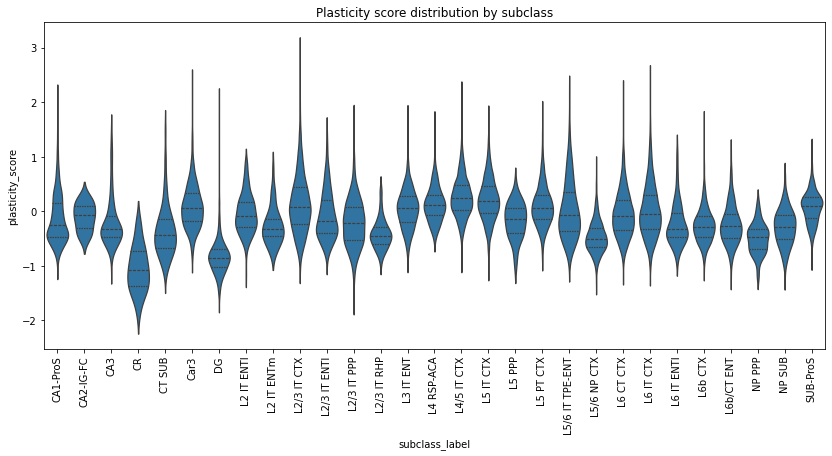

/tmp/ipykernel_8231/1041005322.py:17: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


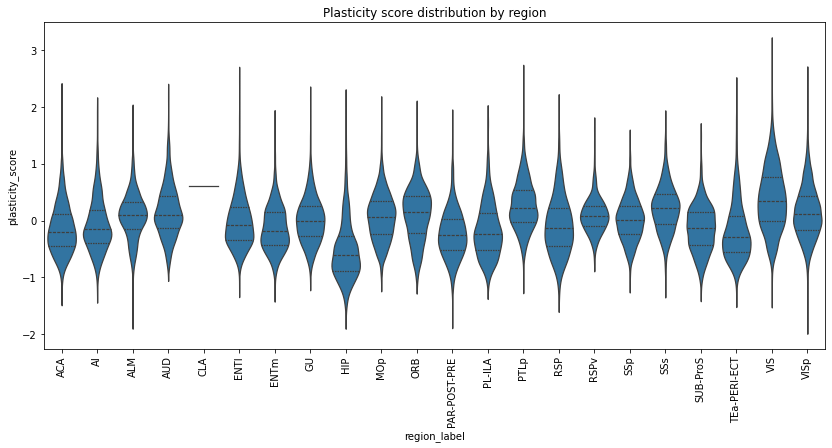

ValueError: The condensed distance matrix must contain only finite values.

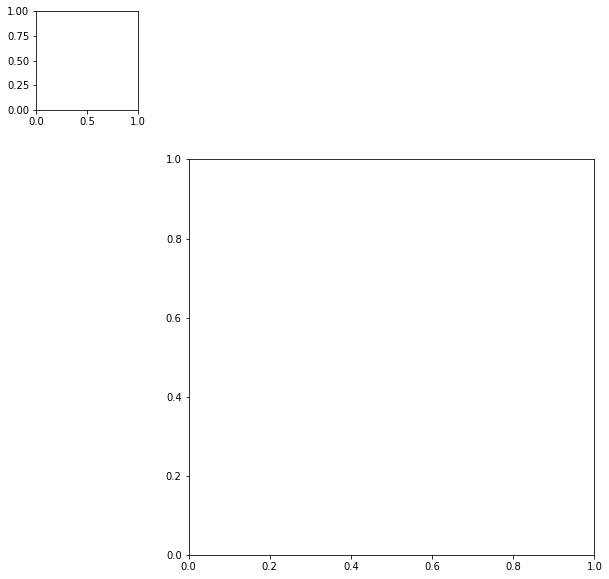